<div style="border:1px solid #d8e2ef; border-radius:18px; padding:26px 30px; background:#ffffff;">
  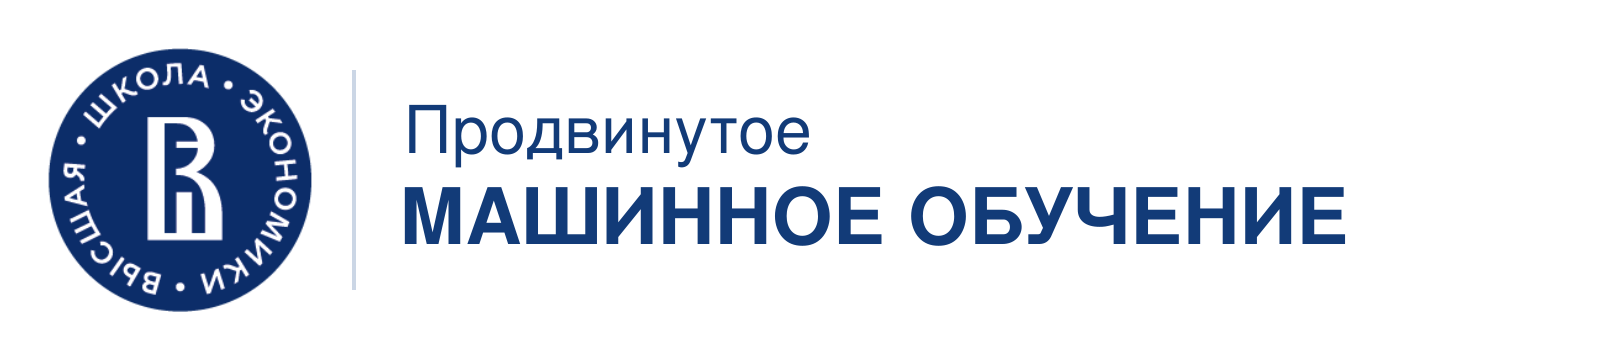
  <h1 style="margin:0 0 8px;color:#163e7b">Семинар №5</h1>
  <h2 style="margin:0 0 12px;color:#163e7b">Градиентный и ньютоновский бустинг</h2>
  <span style="color:#526277">ФКН ВШЭ, 2026–2027</span>
</div>

Сегодня на одной бинарной табличной задаче посмотрим, как дерево учится давать поправку к текущему предсказанию. Сначала используем только градиент, затем добавим вторую производную. В конце обучим XGBoost с тем же типом loss.

### 1. Данные и отправная точка

Встроенный датасет `breast_cancer`: числовые характеристики образцов и бинарная метка. Отложим 25% объектов для проверки; нормализация признаков деревьям не требуется. В этой версии данных `y = 1` означает *benign*.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

data = load_breast_cancer(as_frame=True)
X_train, X_val, y_train, y_val = train_test_split(
    data.data, data.target, test_size=0.25, random_state=42,
    stratify=data.target,
)
print(f"Обучение: {X_train.shape}, валидация: {X_val.shape}")
print(f"Доля класса 1 в обучении: {y_train.mean():.3f}")
X_train.head(3)

Обучение: (426, 30), валидация: (143, 30)
Доля класса 1 в обучении: 0.627


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
517,19.89,20.26,130.50,1214.0,0.10370,0.13100,0.1411,0.09431,0.1802,0.06188,...,23.73,25.23,160.5,1646.0,0.14170,0.3309,0.4185,0.16130,0.2549,0.09136
287,12.89,13.12,81.89,515.9,0.06955,0.03729,0.0226,0.01171,0.1337,0.05581,...,13.62,15.54,87.4,577.0,0.09616,0.1147,0.1186,0.05366,0.2309,0.06915
25,17.14,16.40,116.00,912.7,0.11860,0.22760,0.2229,0.14010,0.3040,0.07413,...,22.25,21.40,152.4,1461.0,0.15450,0.3949,0.3853,0.25500,0.4066,0.10590


Для бинарной классификации ансамбль хранит **логит** $z=F(x)$, а вероятность получается как $p=\sigma(z)$. Начнём с одного постоянного логита $z_0=\operatorname{logit}(\overline y_{\rm train})$. Такой прогноз выдаёт долю класса 1 на обучении.

In [ ]:
p0 = y_train.mean()
z0 = logit(p0)
print(f"Начальная вероятность: {p0:.3f}; логит: {z0:.3f}")
print(f"Log loss на валидации до первого дерева: {log_loss(y_val, np.full(len(y_val), p0)):.3f}")

Начальная вероятность: 0.627; логит: 0.518
Log loss на валидации до первого дерева: 0.659


### 2. Что получает дерево на текущем шаге?

Для логистической потери $\ell(y,z)=\log(1+e^z)-yz$:

$$g_i = \frac{\partial\ell_i}{\partial z_i}=p_i-y_i,\qquad
h_i = \frac{\partial^2\ell_i}{\partial z_i^2}=p_i(1-p_i).$$

- **Первый порядок:** обучаем дерево предсказывать $-g_i$, затем подбираем общий множитель $\gamma$ для его выхода.
- **Второй порядок:** обучаем дерево предсказывать $-g_i/h_i$ с весом объекта $h_i$. Для уже выбранного листа $I_j$ получится $w_j=-\sum_{i\in I_j}g_i/\sum_{i\in I_j}h_i$.

Здесь $h_i$ — одно число на объект, поскольку у него один логит. Параметр $\eta$ позже уменьшит каждую найденную поправку.

#### Иллюстрация: что добавляет вторая производная

Один объект с $y=1$ и текущим логитом $z=-1$. Синяя прямая использует только наклон $g$ и задаёт направление, зелёная парабола учитывает ещё кривизну $h$ и даёт конечный локальный шаг. Значения loss на графике — для **одного** объекта.

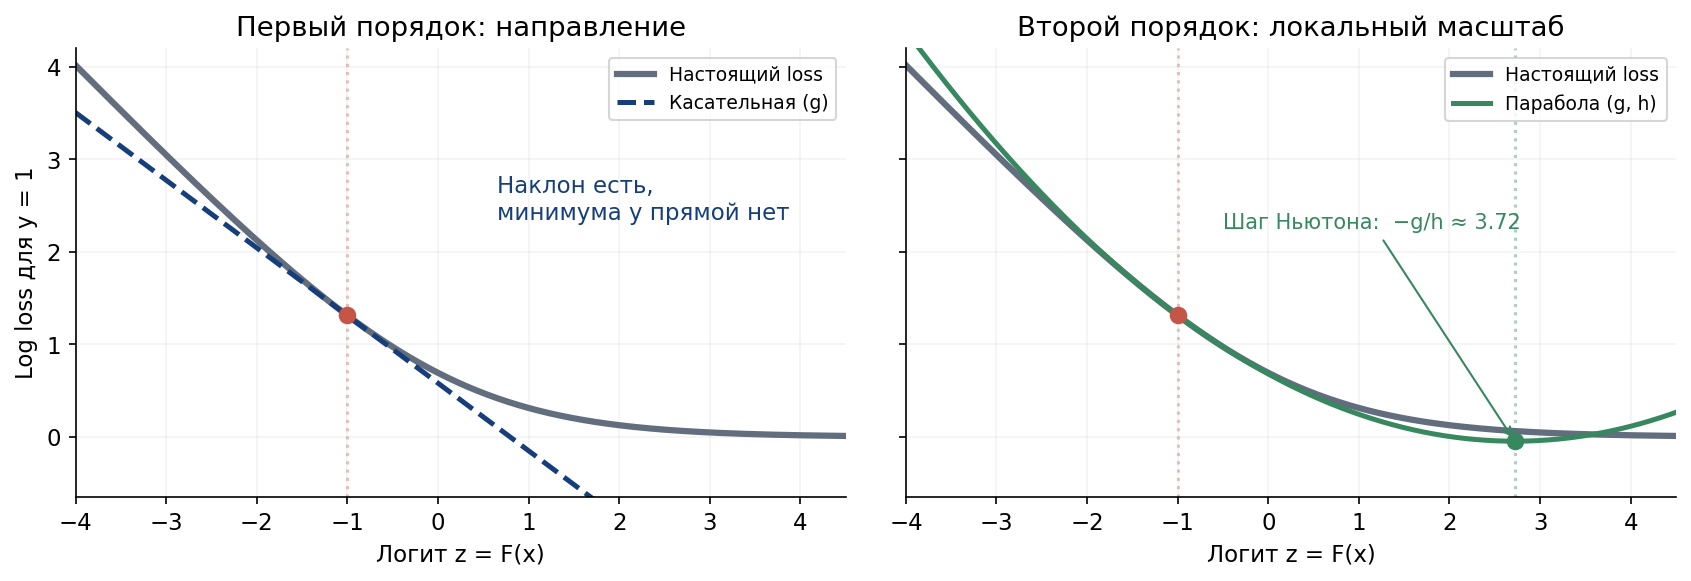

Парабола служит локальным приближением: её минимум может уйти ниже нулевого loss. В бустинге найденную поправку дополнительно уменьшают с помощью $\eta$.

In [ ]:
y_np = y_train.to_numpy()
g0 = np.full(len(y_np), p0) - y_np # p0 - y_np
h0 = np.full(len(y_np), p0 * (1 - p0))
example = pd.DataFrame({
    "y": y_np[:6], "p": p0,
    "антиградиент −g": -g0[:6],
    "кривизна h": h0[:6],
    "шаг Ньютона −g/h": (-g0 / h0)[:6],
})
display(example.round(3))

,y,p,антиградиент −g,кривизна h,шаг Ньютона −g/h
0,0,0.627,-0.627,0.234,-2.679
1,1,0.627,0.373,0.234,1.596
2,0,0.627,-0.627,0.234,-2.679
3,0,0.627,-0.627,0.234,-2.679
4,0,0.627,-0.627,0.234,-2.679
5,0,0.627,-0.627,0.234,-2.679


**Обсудим:** почему в самой первой итерации все значения $h_i$ одинаковы? Будут ли они одинаковыми после нескольких деревьев?

#### Иллюстрация: как из индивидуальных шагов получается значение листа

Четыре **условных** объекта с одним признаком; дерево делит их при $x=2.5$. Высота кружка — индивидуальный шаг $-g_i/h_i$, площадь кружка растёт с весом $h_i$. Горизонтальная линия в каждой области — общая поправка листа до множителя $\eta$.

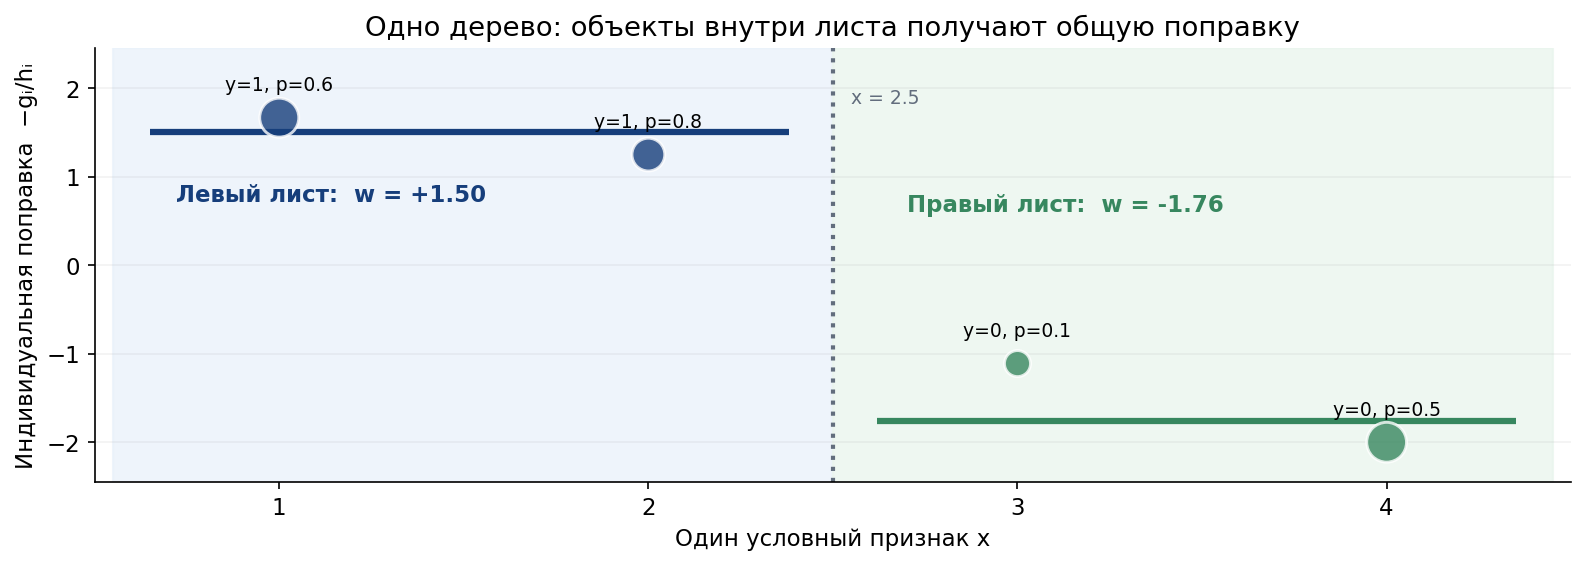

Слева $G=-0.6$, $H=0.4$, поэтому $w=-G/H=+1.5$; справа $G=+0.6$, $H=0.34$, поэтому $w\approx-1.76$. К каждому объекту в одном листе применяется одно и то же $w$, хотя индивидуальные шаги различаются. Здесь $\lambda=0$.

# Расчет параметров G и H для листьев дерева

Для логистической функции потерь (logloss) градиент $g_i$ и гессиан $h_i$ отдельного объекта рассчитываются по формулам:
* $g_i = p_i - y_i$
* $h_i = p_i(1 - p_i)$

Суммарные показатели листа ($G$ и $H$) находятся как сумма индивидуальных значений объектов, попавших в этот лист. Вес листа рассчитывается по формуле $w = -G/H$ (при $\lambda = 0$).

---

## Левый лист (Объекты 1 и 2)

### 1. Расчет градиентов (G)
* **Объект 1** ($y = 1, p = 0.6$): $g_1 = 0.6 - 1 = -0.4$
* **Объект 2** ($y = 1, p = 0.8$): $g_2 = 0.8 - 1 = -0.2$

$$G_{\text{левый}} = (-0.4) + (-0.2) = -0.6$$

### 2. Расчет гессианов (H)
* **Объект 1**: $h_1 = 0.6 \times (1 - 0.6) = 0.24$
* **Объект 2**: $h_2 = 0.8 \times (1 - 0.8) = 0.16$

$$H_{\text{левый}} = 0.24 + 0.16 = 0.4$$

### 3. Расчет веса листа (w)
$$w_{\text{левый}} = -\frac{-0.6}{0.4} = +1.50$$

---

## Правый лист (Объекты 3 и 4)

### 1. Расчет градиентов (G)
* **Объект 3** ($y = 0, p = 0.1$): $g_3 = 0.1 - 0 = +0.1$
* **Объект 4** ($y = 0, p = 0.5$): $g_4 = 0.5 - 0 = +0.5$

$$G_{\text{правый}} = 0.1 + 0.5 = +0.6$$

### 2. Расчет гессианов (H)
* **Объект 3**: $h_3 = 0.1 \times (1 - 0.1) = 0.09$
* **Объект 4**: $h_4 = 0.5 \times (1 - 0.5) = 0.25$

$$H_{\text{правый}} = 0.09 + 0.25 = 0.34$$

### 3. Расчет веса листа (w)
$$w_{\text{правый}} = -\frac{0.6}{0.34} \approx -1.76$$


### 3. Два небольших бустинга своими руками

Одинаковая глубина, листья и скорость обучения: меняем только способ построения поправки. Для первого порядка общий множитель $\gamma$ подбирается минимизацией обучающего log loss вдоль направления дерева. Для второго порядка `sample_weight=h` даёт взвешенные средние $-g/h$ в листьях — именно формулу выше при $\lambda=0$. `DecisionTreeRegressor` здесь строит разбиения по взвешенной квадратичной ошибке; готовый XGBoost дополнительно учитывает регуляризацию и свой алгоритм поиска разбиений.

In [ ]:
# объявление функции бустинга с выбором метода оптимизации, числа деревьев и темпа обучения
def fit_small_boosting(order, n_trees=70, eta=0.1):
    # инициализация логов (сырых предсказаний) тренировочной выборки базовым значением z0
    train_z = np.full(len(X_train), z0)
    # инициализация логов валидационной выборки базовым значением z0
    val_z = np.full(len(X_val), z0)
    # расчет стартовой ошибки на трейне (expit переводит логиты z в вероятности p)
    train_curve = [log_loss(y_train, expit(train_z))]
    # расчет стартовой ошибки на валидации
    val_curve = [log_loss(y_val, expit(val_z))]

    # запуск цикла поочередного построения n_trees базовых деревьев
    for step in range(n_trees):
        # вычисление текущих вероятностей для тренировочных объектов
        p = expit(train_z)
        # расчет градиента (ошибок) для каждого объекта выборки
        g = p - y_np
        # расчет гессиана (кривизны) с защитой от деления на ноль с помощью нижней границы
        h = np.maximum(p * (1 - p), 1e-8)
        # создание структуры решающего дерева глубины 2 с фиксацией случайности
        tree = DecisionTreeRegressor(
            max_depth=2, min_samples_leaf=20, random_state=step
        )
        # ветвление, если выбран обычный градиентный бустинг первого порядка
        if order == "gradient": # если выбрали первый порядок
            # обучение дерева предсказывать антиградиент на основе признаков трейна
            tree.fit(X_train, -g)
            # получение сдвигов (направления шага) из обученного дерева для трейна
            direction = tree.predict(X_train)
            # одномерная оптимизация для поиска наилучшей длины шага (гаммы) - ЛАЙН СЕРЧ (LINE SEARCH)
            gamma = minimize_scalar(
                # минимизация logloss по параметру 'a' (длине шага) вдоль направления direction
                lambda a: np.mean(np.logaddexp(0, train_z + a * direction) # логлосс
                                  - y_np * (train_z + a * direction)),
                # ограничение поиска оптимального множителя в диапазоне от 0 до 20
                bounds=(0, 20), method="bounded",
            ).x # извлечение найденного оптимального значения скаляра
        # ветвление, если выбран бустинг второго порядка (метод Ньютона-Рафсона)
        elif order == "newton":
            # обучение на индивидуальные шаги Ньютона с весами объектов, равными гессианам
            tree.fit(X_train, -g / h, sample_weight=h)
            # фиксированный шаг, так как кривизна лосс-функции уже учтена внутри листьев
            gamma = 1.0
        # обработка ошибки в случае передачи некорректного имени метода
        else:
            raise ValueError("order: 'gradient' или 'newton'")

        # обновление логов трейна: прибавление шага нового дерева с учетом темпа обучения и гаммы
        train_z += eta * gamma * tree.predict(X_train)
        # аналогичное обновление логов для валидационной выборки
        val_z += eta * gamma * tree.predict(X_val)
        # расчет и сохранение текущей ошибки на трейне после добавления дерева
        train_curve.append(log_loss(y_train, expit(train_z)))
        # расчет и сохранение текущей ошибки на валидации после добавления дерева
        val_curve.append(log_loss(y_val, expit(val_z)))

    # возврат финальных предсказаний-вероятностей и массивов с историей изменения ошибок
    return expit(val_z), np.array(train_curve), np.array(val_curve)

# запуск обучения модели первого порядка (классический градиентный бустинг)
first_p, first_train, first_val = fit_small_boosting("gradient")
# запуск обучения модели второго порядка (ньютоновский бустинг, аналог xgboost)
second_p, second_train, second_val = fit_small_boosting("newton")

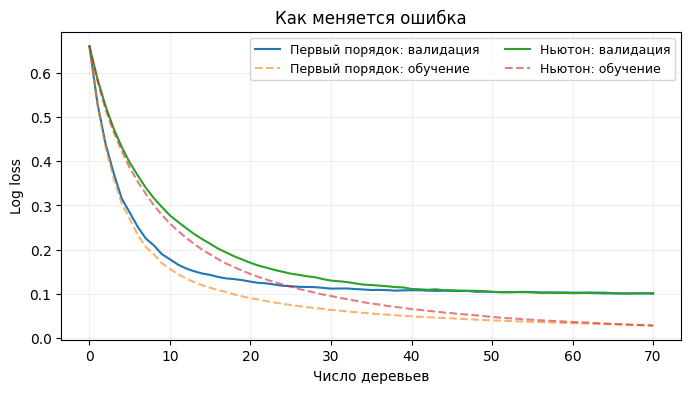

,Модель,Log loss (валидация),ROC AUC (валидация)
0,Константа,0.659,0.500
1,Первый порядок,0.101,0.993
2,Ньютон,0.102,0.994


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, train, val in [
    ("Первый порядок", first_train, first_val),
    ("Ньютон", second_train, second_val),
]:
    ax.plot(val, label=f"{label}: валидация")
    ax.plot(train, linestyle="--", alpha=0.6, label=f"{label}: обучение")
ax.set(xlabel="Число деревьев", ylabel="Log loss", title="Как меняется ошибка")
ax.legend(ncol=2, fontsize=9)
ax.grid(alpha=0.2)
plt.show()

comparison = pd.DataFrame({
    "Модель": ["Константа", "Первый порядок", "Ньютон"],
    "Log loss (валидация)": [first_val[0], first_val[-1], second_val[-1]],
    "ROC AUC (валидация)": [0.5, roc_auc_score(y_val, first_p),
                             roc_auc_score(y_val, second_p)],
})
display(comparison.round(3))

**Вопросы к графику:** (1) одинаковы ли два метода по качеству на этой выборке? (2) почему более низкий *обучающий* loss не обязательно означает более низкий *валидационный*? (3) что изменится, если увеличить глубину дерева с 2 до 5?

**Важная оговорка:** это учебные реализации, а не точные копии библиотечных алгоритмов. Их кривые нельзя трактовать как универсальное доказательство превосходства одного порядка над другим: результат зависит от данных и настроек.

### 4. Как это выглядит в библиотеке: XGBoost

Ниже аналогичная задача с регуляризацией листьев `reg_lambda=1`. `objective="binary:logistic"` задаёт логистическую потерю, а `predict_proba` возвращает вероятность класса 1.

In [ ]:
%pip -q install xgboost

In [ ]:
try:
    from xgboost import XGBClassifier
except ImportError:
    print("XGBoost пока не установлен; основной разбор выше уже выполнен.")
else:
    xgb_model = XGBClassifier(
        n_estimators=70, max_depth=2, learning_rate=0.1,
        min_child_weight=1, reg_lambda=1,
        objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", random_state=42, n_jobs=2,
    )
    xgb_model.fit(X_train, y_train)
    xgb_p = xgb_model.predict_proba(X_val)[:, 1]
    print(f"XGBoost: log loss = {log_loss(y_val, xgb_p):.3f}; "
          f"ROC AUC = {roc_auc_score(y_val, xgb_p):.3f}")
    display(pd.Series(xgb_model.feature_importances_, index=X_train.columns)
            .sort_values(ascending=False).head(8).rename("Важность признака"))

XGBoost: log loss = 0.098; ROC AUC = 0.994


,Важность признака
worst radius,0.204916
worst perimeter,0.197252
mean concave points,0.161413
worst concave points,0.127899
texture error,0.051726
worst area,0.031929
mean area,0.021958
worst texture,0.021572
